### Dwell position spacing 1 - 5 mm @ 1e6 histories

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2025/modulated_shielding")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [2]:
## Define basic optimization parameters ##
# These parameters from Alterovitz et al. (2006) - for dose to prostate surface 
D_min = 9.5 # Gy
D_max = 15 # Gy
M_l = 100 # penalty/Gy
M_u = 100 # penalty/Gy

num_dose_points = 8

In [3]:
# Debugging number of dwell positions given a particular spacing
test1 = np.array([x for x in np.arange(-25, 0, 2)])
test2 = np.array([x for x in np.arange(0, 26, 2)])
print(len(np.hstack((test1, test2))))

26


#### Spacing = 1 mm

In [4]:
num_dwell_pos_1 = 51

# Unpack the dose rate matrix from the locally stored file
D_1 = np.load("D_1mmSpace_1e6.npy")

func_1, x_1, __ = linear_penalty(D_min, D_max, M_l, M_u, num_dose_points, num_dwell_pos_1, D_1)

#### Spacing = 2 mm

In [5]:
num_dwell_pos_2 = 26

# Unpack the dose rate matrix from the locally stored file
D_2 = np.load("D_2mmSpace_1e6.npy")

func_2, x_2, __ = linear_penalty(D_min, D_max, M_l, M_u, num_dose_points, num_dwell_pos_2, D_2)

#### Spacing = 3 mm

In [6]:
num_dwell_pos_3 = 18

# Unpack the dose rate matrix from the locally stored file
D_3 = np.load("D_3mmSpace_1e6.npy")

func_3, x_3, __ = linear_penalty(D_min, D_max, M_l, M_u, num_dose_points, num_dwell_pos_3, D_3)

#### Spacing = 4 mm

In [7]:
num_dwell_pos_4 = 14

# Unpack the dose rate matrix from the locally stored file
D_4 = np.load("D_4mmSpace_1e6.npy")

func_4, x_4, __ = linear_penalty(D_min, D_max, M_l, M_u, num_dose_points, num_dwell_pos_4, D_4)

#### Spacing = 5 mm

In [19]:
num_dwell_pos_5 = 11

# Unpack the dose rate matrix from the locally stored file
D_5 = np.load("D_5mmSpace_1e6.npy")

func_5, x_5, __ = linear_penalty(D_min, D_max, M_l, M_u, num_dose_points, num_dwell_pos_5, D_5)

In [21]:
# Plot dwell time vs dwell position index
dwell_pos_cm5 = np.array([x for x in np.arange(-25, 26, 5)])
#dwell_pos_time5 = x_5[0:num_dwell_pos_5]
# Save dwell position times for portability to another sheet
#np.save("dwell_pos_time_1mm.npy", dwell_pos_time)

#fig5, ax5 = plt.subplots()
#ax5.bar(dwell_pos_cm5, x_5)
#ax5.set_xlabel('dwell position pos (cm)')
#ax5.set_ylabel('dwell position time (sec)')
#plt.show()

#### Plotting

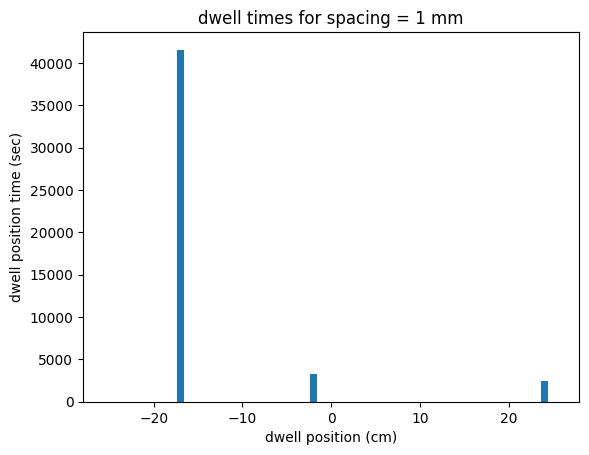

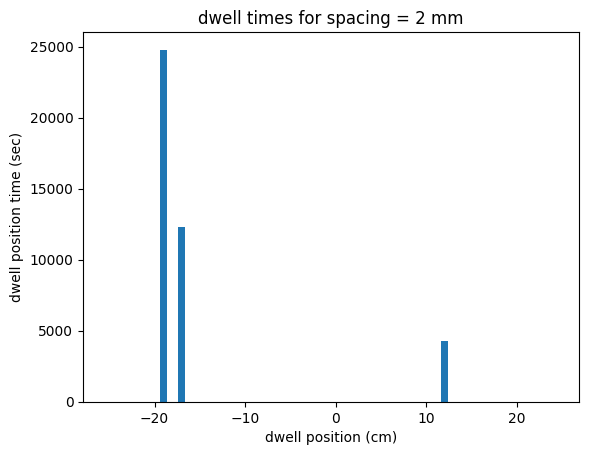

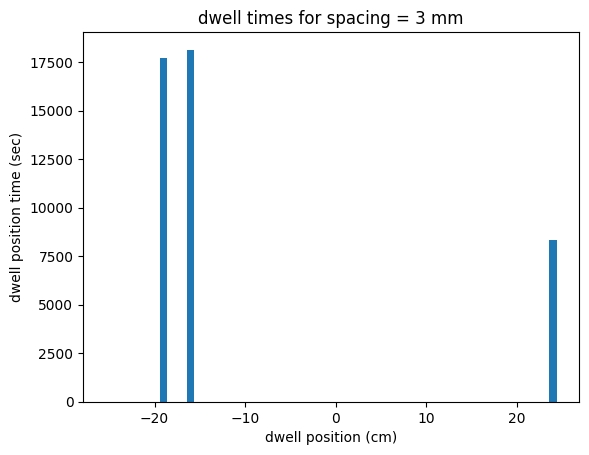

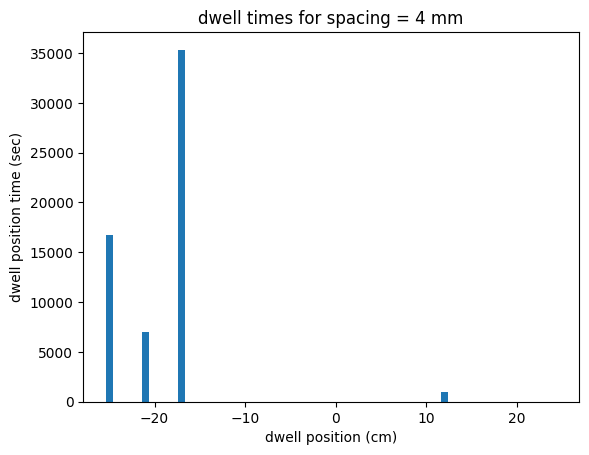

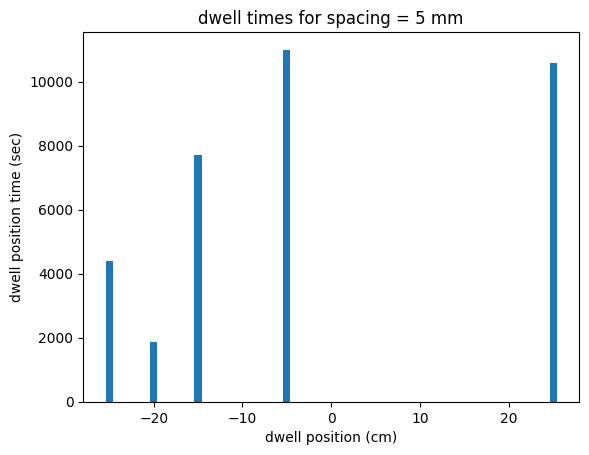

In [22]:
results = (x_1, x_2, x_3, x_4, x_5)

for i, x in enumerate(results):
    cm_1 = np.array([x for x in np.arange(-25, 0, i+1)])
    cm_2 = np.array([x for x in np.arange(0, 26, i+1)])
    dwell_pos_cm = np.hstack((cm_1, cm_2))
    
    #dwell_pos_time = x[0:np.shape(x)[0]]

    fig, ax = plt.subplots()
    ax.bar(dwell_pos_cm, x)
    ax.set_title("dwell times for spacing = " + str(i + 1) + " mm")
    ax.set_xlabel('dwell position (cm)')
    ax.set_ylabel('dwell position time (sec)')
    plt.show()